# Capítulo 6 · OE3

Lee `../team/` (fuera de git: claves, audio y respuestas del equipo) y escribe `../figures/`. Las personas van como A y B.

In [1]:
import json
import re
import sys
import xml.etree.ElementTree as ET
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torchvision.ops import box_iou

sys.path.insert(0, str(next(p for p in Path.cwd().parents if (p / "pyproject.toml").exists()) / "src"))
from analysis.review import BOX, LABEL, MATCH, categorize, load_annotations, xyxy
from core.config import PROJECT_DIR, RAW_DIR, P
from data.annotations import clean_annotations
from data.raven import BEGIN, CALL, END, HIGH, LOW, SCORE, SPECIES
from evaluation.evaluator import RawPredictions
from utils.figuras import ANCHO, Salidas, anotada, caja, cargar, espectrograma, leyenda, number, percent, predicha

TEAM = Path.cwd().parent / "team"
DATA, ANSWERS, SESSION = TEAM / "data", TEAM / "answers", TEAM / "package/1_timed_session"
CHECK_AUDIO = TEAM / "package/2_check_boxes/audio"
OUT = Salidas("06_oe3_revision")
RUN_DIR = PROJECT_DIR / "runs/yolo26s_v3"
dataset = json.loads((RUN_DIR / "config.json").read_text())["dataset"]
NAMES = RawPredictions.load(RUN_DIR / "yolo26s_v3_test_predictions.pt").labels
SUMMARY = json.loads((DATA / "test_summary.json").read_text())
HOURS = SUMMARY["hours"]
CH5 = dict(re.findall(r"\\newcommand\{\\(\w+)\}\{([^}]*)\}",
                      (PROJECT_DIR / "research/capitulos/05_oe2_detector/figures/valores.tex").read_text()))
WORDS = ["correct", "box", "other", "no", "?"]
REAL = ["correct", "box", "other"]  # hay una llamada de primate en la caja
STRATA = ["none_alta", "none_media", "none_baja", BOX, LABEL, MATCH]
NONE_STRATA = STRATA[:3]
STRATUM_NAMES = dict(zip(STRATA, ["Nada anotado, $>$ 0,5", "Nada anotado, 0,3--0,5",
                                  "Nada anotado, 0,11--0,3", "Caja distinta", "Otra llamada",
                                  "Acierto (control)"]))
CLEANED = ["begin_time_s", "end_time_s", "low_freq_hz", "high_freq_hz"]

In [2]:
XLSX = {"m": "http://schemas.openxmlformats.org/spreadsheetml/2006/main"}


def read_sheet(path: Path) -> pd.DataFrame:
    # Una planilla devuelta, .csv o .xlsx (la primera hoja, sin openpyxl: es un zip de XML)
    if path.suffix != ".xlsx":
        return pd.read_csv(path, sep=None, engine="python", dtype=str, keep_default_na=False)
    book, tag = zipfile.ZipFile(path), f"{{{XLSX['m']}}}t"
    shared = []
    if "xl/sharedStrings.xml" in book.namelist():
        root = ET.fromstring(book.read("xl/sharedStrings.xml"))
        shared = ["".join(t.text or "" for t in si.iter(tag)) for si in root.findall("m:si", XLSX)]
    rows = []
    for row in ET.fromstring(book.read("xl/worksheets/sheet1.xml")).iter(f"{{{XLSX['m']}}}row"):
        cells = {}
        for cell in row.findall("m:c", XLSX):
            column = 0
            for letter in re.match(r"[A-Z]+", cell.get("r")).group(0):
                column = column * 26 + ord(letter) - 64
            if cell.get("t") == "inlineStr":
                cells[column - 1] = "".join(t.text or "" for t in cell.iter(tag))
            elif (value := cell.find("m:v", XLSX)) is not None:
                cells[column - 1] = shared[int(value.text)] if cell.get("t") == "s" else value.text
        rows.append(cells)
    width = max((max(c) for c in rows if c), default=-1) + 1
    header = [rows[0].get(i, f"col{i}") for i in range(width)]
    return pd.DataFrame([[r.get(i, "") for i in range(width)] for r in rows[1:]], columns=header)


def wilson(k: float, n: float, z: float = 1.96) -> tuple[float, float]:
    p = k / n
    center = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return max(center - half, 0.0), min(center + half, 1.0)


def listing(items: list[str]) -> str:
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + " y " + items[-1]

In [3]:
# Tarea 2. Erratas de `answer`, corregidas a la vista; «too short» es el comentario típico de `box`.
TYPOS = {"corect": "correct", "too short": "box"}


def read_answers(prefix: str) -> pd.DataFrame:
    paths = sorted([*ANSWERS.rglob("boxes*.csv"), *ANSWERS.rglob("boxes*.xlsx")])
    sheets = [read_sheet(p) for p in paths]
    sheets = [s[s.ID.str.startswith(prefix)].assign(answer=lambda s: s.answer.str.strip().str.lower())
              for s in sheets]
    sheet = max(sheets, key=lambda s: (s.answer != "").sum())
    print("erratas:", dict(sheet.loc[sheet.answer.isin(TYPOS), ["ID", "answer"]].to_numpy()))
    sheet = sheet.assign(answer=sheet.answer.replace(TYPOS))
    assert sheet.answer.isin([*WORDS, ""]).all(), set(sheet.answer) - set(WORDS)
    return sheet[sheet.answer != ""]


def reading(stratum: str, answer: str) -> str:
    # La categoría del IOV según de dónde salió la caja (protocolo, §5; Tabla 6.1)
    if answer == "?":
        return "incierto"
    if stratum == MATCH:
        return "acierto confirmado" if answer == "correct" else "desacuerdo con la referencia"
    if answer == "no":
        return "ruido"
    if stratum.startswith("none"):
        return "evento no anotado"
    return {"correct": "anotación por corregir", "other": "error de clase"}.get(answer, "error de encuadre")


key = pd.read_csv(DATA / "check_boxes_key.csv")
population = pd.read_csv(DATA / "test_population.csv")
size = population.stratum.value_counts()
items = key.merge(read_answers("C")[["ID", "answer", "comment"]], on="ID", validate="one_to_one")
items["iov"] = [reading(s, a) for s, a in zip(items.stratum, items.answer, strict=True)]
items["species"] = items.label.str.split("/").str[0]
# Cada persona devolvió sus grabaciones en una carpeta de `audio/`: A, B… por orden alfabético
person_dirs = sorted(d for d in (ANSWERS / "audio").glob("*") if d.is_dir())
PERSON = {w.name: letter for letter, d in zip("ABCDEFGH", person_dirs) for w in d.glob("*.wav")}
items["person"] = items.recording.map(lambda r: PERSON.get(Path(r).name, ""))
pd.crosstab(items.stratum, items.iov, margins=True).reindex([*STRATA, "All"])

erratas: {'C046': 'corect', 'C671': 'too short'}


iov,acierto confirmado,anotación por corregir,desacuerdo con la referencia,error de clase,error de encuadre,evento no anotado,incierto,ruido,All
stratum,,,,,,,,,
none_alta,0,0,0,0,0,253,0,47,300
none_media,0,0,0,0,0,165,2,33,200
none_baja,0,0,0,0,0,89,1,43,133
box,0,84,0,25,103,0,1,7,220
label,0,23,0,47,14,0,0,3,87
match,41,0,13,0,0,0,1,5,60
All,41,107,13,72,117,507,5,138,1000


In [4]:
counts = pd.crosstab(items.stratum, items.answer).reindex(index=STRATA, columns=WORDS, fill_value=0)
n = counts.sum(axis=1)
calls = counts[REAL].sum(axis=1)
weight = (size.reindex(NONE_STRATA) / size.reindex(NONE_STRATA).sum()).to_numpy(float)
n_none = n.reindex(NONE_STRATA).to_numpy(float)
N_NONE = int(size.reindex(NONE_STRATA).sum())


def stratified(flag: pd.Series) -> tuple[float, float]:
    # Todo «nada anotado»: cada tramo pesado por su población; intervalo normal, sin corrección
    # por población finita (que lo estrecharía)
    part = flag.groupby(items.stratum).mean().reindex(NONE_STRATA).to_numpy(float)
    return float(weight @ part), float(np.sqrt((weight**2 * part * (1 - part) / n_none).sum()))


strat = {w: stratified(items.answer == w) for w in WORDS} | {"llamada": stratified(items.answer.isin(REAL))}
p_real, se_real = strat["llamada"]
p_noise, se_noise = strat["no"]
counts.assign(n=n, población=size.reindex(STRATA))

answer,correct,box,other,no,?,n,población
stratum,,,,,,,
none_alta,156,53,44,47,0,300,583
none_media,79,54,32,33,2,200,638
none_baja,48,18,23,43,1,133,1016
box,84,103,25,7,1,220,220
label,23,14,47,3,0,87,87
match,41,12,1,5,1,60,2150


In [5]:
def cell(k: float, m: float) -> str:
    low, high = wilson(k, m)
    return f"{100 * k / m:.0f} ({100 * low:.0f}--{100 * high:.0f})"


rows = []
for s in STRATA:
    rows.append([STRATUM_NAMES[s], number(size[s]), number(n[s]),
                 *[cell(counts.loc[s, w], n[s]) for w in REAL + ["no"]], cell(calls[s], n[s])])
    if s == NONE_STRATA[-1]:
        rows += [r"\addlinespace",
                 ["Nada anotado, los tres tramos", number(N_NONE), number(n_none.sum())]
                 + [f"{100 * p:.0f} ({100 * (p - 1.96 * e):.0f}--{100 * (p + 1.96 * e):.0f})"
                    for p, e in (strat[w] for w in [*REAL, "no", "llamada"])],
                 r"\midrule"]
OUT.tabla("estratos", rows)
print((OUT.dir / "tablas/estratos.tex").read_text())

% generado por el cuaderno; no editar
Nada anotado, $>$ 0,5 & 583 & 300 & 52 (46--58) & 18 (14--22) & 15 (11--19) & 16 (12--20) & 84 (80--88) \\
Nada anotado, 0,3--0,5 & 638 & 200 & 40 (33--46) & 27 (21--34) & 16 (12--22) & 16 (12--22) & 82 (77--87) \\
Nada anotado, 0,11--0,3 & 1\,016 & 133 & 36 (28--45) & 14 (9--20) & 17 (12--25) & 32 (25--41) & 67 (59--74) \\
\addlinespace
Nada anotado, los tres tramos & 2\,237 & 633 & 41 (37--46) & 18 (15--22) & 16 (13--20) & 23 (19--28) & 76 (72--80) \\
\midrule
Caja distinta & 220 & 220 & 38 (32--45) & 47 (40--53) & 11 (8--16) & 3 (2--6) & 96 (93--98) \\
Otra llamada & 87 & 87 & 26 (18--37) & 16 (10--25) & 54 (44--64) & 3 (1--10) & 97 (90--99) \\
Acierto (control) & 2\,150 & 60 & 68 (56--79) & 20 (12--32) & 2 (0--9) & 8 (4--18) & 90 (80--95)



In [6]:
controls = items[items.stratum == MATCH]
box_items, label_items = items[items.stratum == BOX], items[items.stratum == LABEL]
category = items.iov.value_counts()
top, bottom = "none_alta", "none_baja"


def share(frame: pd.DataFrame, word: str) -> str:
    return percent((frame.answer == word).mean(), 0)


OUT.valores |= {
    "uCatUnannotated": number(category.get("evento no anotado", 0)),
    "uCatNoise": number(category.get("ruido", 0)),
    "uCatFraming": number(category.get("error de encuadre", 0)),
    "uCatClass": number(category.get("error de clase", 0)),
    "uCatFix": number(category.get("anotación por corregir", 0)),
    "uCatConfirmed": number(category.get("acierto confirmado", 0)),
    "uCatDisagree": number(category.get("desacuerdo con la referencia", 0)),
    "uCatUnsure": number(category.get("incierto", 0)),
    "uItems": number(len(items)),
    "uItemsRecordings": number(items.recording.nunique()),
    "uRows": number(len(population)),
    "uMatchRows": number(size[MATCH]),
    "uNoneRows": number(N_NONE),
    "uNoneSample": number(n_none.sum()),
    "uBoxRows": number(size[BOX]),
    "uLabelRows": number(size[LABEL]),
    "uNotReviewed": number(size.get("other", 0)),
    "uControls": number(len(controls)),
    "uTopSample": number(n[top]),
    "uUnsure": number((items.answer == "?").sum()),
    "uUnsureByStratum": listing([number(counts.loc[s, "?"]) for s in STRATA]),
    "uNoneReal": percent(p_real, 1),
    "uNoneRealLow": percent(p_real - 1.96 * se_real, 1),
    "uNoneRealHigh": percent(p_real + 1.96 * se_real, 1),
    "uNoneRealMargin": number(100 * 1.96 * se_real, 1),
    "uNoneCorrect": percent(strat["correct"][0], 0),
    "uNoneNoise": percent(p_noise, 1),
    "uNoneNoiseLow": percent(p_noise - 1.96 * se_noise, 1),
    "uNoneNoiseHigh": percent(p_noise + 1.96 * se_noise, 1),
    "uNoneRealTop": percent(calls[top] / n[top], 0),
    "uNoneRealTopLow": percent(wilson(calls[top], n[top])[0], 0),
    "uNoneRealTopHigh": percent(wilson(calls[top], n[top])[1], 0),
    "uNoneCorrectTop": percent(counts.loc[top, "correct"] / n[top], 0),
    "uNoneNoiseTop": percent(counts.loc[top, "no"] / n[top], 0),
    "uNoneRealBottom": percent(calls[bottom] / n[bottom], 0),
    "uNoneNoiseBottom": percent(counts.loc[bottom, "no"] / n[bottom], 0),
    "uUnannotated": number(p_real * N_NONE),
    "uUnannotatedLow": number((p_real - 1.96 * se_real) * N_NONE),
    "uUnannotatedHigh": number((p_real + 1.96 * se_real) * N_NONE),
    "uUnannotatedPerHour": number(p_real * N_NONE / HOURS),
    "uNoisePerHour": number(p_noise * N_NONE / HOURS),
    "uBoxModelOk": share(box_items, "correct"),
    "uBoxModelFraming": share(box_items, "box"),
    "uBoxModelClass": share(box_items, "other"),
    "uBoxModelNoise": share(box_items, "no"),
    "uLabelModelOk": share(label_items, "correct"),
    "uLabelModelWrong": share(label_items, "other"),
    "uLabelModelFraming": share(label_items, "box"),
    "uControlsOk": share(controls, "correct"),
    "uControlsFraming": share(controls, "box"),
    "uControlsNoise": share(controls, "no"),
    "uControlsNoiseN": number((controls.answer == "no").sum()),
    "uControlsBird": number(((controls.answer == "no") & controls.comment.str.lower().str.contains("bird")).sum()),
    "uTestRecordings": number(SUMMARY["recordings"]),
    "uTestHours": number(HOURS, 2),
}

In [7]:
# La referencia de prueba con la misma regla (clases del modelo, sin revisión ni clases de ventana)
annotations = load_annotations(dataset["joined_labels"])
cpu = pd.read_csv(DATA / "test_cpu_times.csv")
in_test = annotations[annotations.recording.isin(cpu.recording)]
reference_test = in_test[~in_test.requires_review & in_test.label.isin(NAMES)
                         & ~in_test.label.isin(["as/hc", "pt/dc"])]
found = population.loc[population.category == MATCH, "annotation"].nunique()
OUT.valores |= {
    "uRefTest": number(len(reference_test)),
    "uRefPerHour": number(len(reference_test) / HOURS),
    "uRecallRows": number(found / len(reference_test), 2),
}

In [8]:
# Sensibilidad 1: cajas «nada anotado» con al menos la mitad dentro de una anotación de otra clase
def inside_share(boxes: pd.DataFrame, others: pd.DataFrame) -> np.ndarray:
    if others.empty:
        return np.zeros(len(boxes))
    b, r = xyxy(boxes, [BEGIN, END, LOW, HIGH]), xyxy(others, CLEANED)
    inter = (torch.min(b[:, None, 2:], r[None, :, 2:]) - torch.max(b[:, None, :2], r[None, :, :2]))
    area = ((b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])).clamp(min=1e-9)
    return (inter.clamp(min=0).prod(-1) / area[:, None]).max(dim=1).values.numpy()


items["inside"] = False
for recording, group in items[items.stratum.isin(NONE_STRATA)].groupby("recording"):
    items.loc[group.index, "inside"] = inside_share(group, in_test[in_test.recording == recording]) >= 0.5
p_kept, _ = stratified(items.answer.isin(REAL) & ~items.inside)
inside = items[items.inside]
OUT.valores |= {
    "uNoneInside": number(len(inside)),
    "uNoneInsideOther": number((inside.answer == "other").sum()),
    "uNoneRealKept": percent(p_kept, 1),
    "uUnannotatedKeptPerHour": number(p_kept * N_NONE / HOURS),
}
inside.answer.value_counts()

answer
other      22
box         4
correct     4
Name: count, dtype: int64

In [9]:
# Sensibilidad 2: remuestreo de grabaciones dentro de cada estrato
rng = np.random.default_rng(42)
groups = {s: [g for _, g in items[items.stratum == s].groupby("recording")] for s in STRATA}
draws = []
for _ in range(2000):
    sample = {s: pd.concat([g[i] for i in rng.integers(0, len(g), len(g))]) for s, g in groups.items()}
    draws.append((weight @ [sample[s].answer.isin(REAL).mean() for s in NONE_STRATA],
                  (sample[LABEL].answer == "other").mean()))
(real_low, other_low), (real_high, other_high) = np.percentile(draws, [2.5, 97.5], axis=0)
label_ci = wilson((label_items.answer == "other").sum(), len(label_items))
OUT.valores |= {
    "uNoneRealBootLow": percent(real_low, 1),
    "uNoneRealBootHigh": percent(real_high, 1),
    "uNoneRealBootMargin": number(100 * (real_high - real_low) / 2, 1),
    "uLabelOtherLow": percent(label_ci[0], 0),
    "uLabelOtherHigh": percent(label_ci[1], 0),
    "uLabelOtherBootLow": percent(other_low, 0),
    "uLabelOtherBootHigh": percent(other_high, 0),
    "uLabelLargestRecording": number(label_items.recording.value_counts().iloc[0]),
    "uLabelRecordings": number(label_items.recording.nunique()),
}

In [10]:
# El error aparente según el revisor: cada estrato llevado a su población
estimate = pd.DataFrame({w: [size[s] * (items[items.stratum == s].answer == w).mean() for s in STRATA]
                         for w in WORDS}, index=STRATA)
apparent = estimate.drop(index=MATCH).sum()
total = estimate.sum()
reviewable = int(size.reindex(STRATA).sum())
OUT.valores |= {
    "uApparent": number(apparent.sum()),
    "uApparentCorrect": percent(apparent["correct"] / apparent.sum(), 0),
    "uApparentBox": percent(apparent["box"] / apparent.sum(), 0),
    "uApparentOther": percent(apparent["other"] / apparent.sum(), 0),
    "uApparentNoise": percent(apparent["no"] / apparent.sum(), 0),
    "uReviewable": number(reviewable),
    "uPrecisionRef": number(size[MATCH] / len(population), 2),
    "uPrecisionStrict": number(total["correct"] / reviewable, 2),
    "uPrecisionLenient": number((total["correct"] + total["box"]) / reviewable, 2),
    "uPrecisionCall": number(total[REAL].sum() / reviewable, 2),
    "uNoiseShareAll": percent(total["no"] / reviewable, 0),
}
(apparent / apparent.sum()).round(3)

correct    0.404
box        0.208
other      0.171
no         0.210
?          0.006
dtype: float64

In [11]:
# El ruido según los comentarios, y su relación con la confianza
noise_notes = items.loc[items.answer == "no", "comment"].str.lower()
SOURCES = {"bird": "uNoBird", "backgro": "uNoBackground", "insect": "uNoInsect", "human": "uNoHuman"}
none_items = items[items.stratum.isin(NONE_STRATA)].copy()
none_items["tramo"] = pd.cut(none_items.score, [0.11, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 1.0], right=False)
trend = none_items.groupby("tramo", observed=True).answer.agg(
    n="size", llamada=lambda a: a.isin(REAL).mean(), ruido=lambda a: (a == "no").mean())
OUT.valores |= {macro: number(noise_notes.str.contains(word).sum()) for word, macro in SOURCES.items()}
OUT.valores |= {
    "uNoAnswers": number(len(noise_notes)),
    "uNoiseFirstBin": percent(trend.ruido.iloc[0], 0),
    "uNoiseLastBin": percent(trend.ruido.iloc[-1], 0),
    "uRealFirstBin": percent(trend.llamada.iloc[0], 0),
    "uRealLastBin": percent(trend.llamada.iloc[-1], 0),
}
trend.round(3)

,n,llamada,ruido
tramo,,,
"[0.11, 0.2)",82,0.622,0.366
"[0.2, 0.3)",51,0.745,0.255
"[0.3, 0.4)",114,0.798,0.193
"[0.4, 0.5)",86,0.860,0.128
"[0.5, 0.6)",151,0.821,0.179
"[0.6, 0.7)",85,0.859,0.141
"[0.7, 1.0)",64,0.875,0.125


In [12]:
# Dónde está el ruido y qué clases se confunden
classes = none_items.groupby("label").answer.agg(
    n="size", no=lambda a: (a == "no").sum(), other=lambda a: (a == "other").sum())
classes = classes[classes.n >= 10]
by_species = none_items.groupby("species").answer.apply(lambda a: (a == "no").mean()).sort_values(ascending=False)
top_noise, top_other = classes.no.idxmax(), (classes.other / classes.n).idxmax()
same = label_items.label.str.split("/").str[0] == label_items.annotated_as.str.split("/").str[0]
cross = label_items[~same]
OUT.valores |= {
    "uNoiseTopClass": f"\\code{{{top_noise}}}",
    "uNoiseTopK": number(classes.no[top_noise]),
    "uNoiseTopN": number(classes.n[top_noise]),
    "uNoiseTopShare": percent(classes.no[top_noise] / classes.n[top_noise], 0),
    "uNoiseBySpecies": listing([f"{s.upper()} {percent(v, 0)}" for s, v in by_species.items()]),
    "uOtherTopClass": f"\\code{{{top_other}}}",
    "uOtherTopK": number(classes.other[top_other]),
    "uOtherTopN": number(classes.n[top_other]),
    "uLabelSameSpecies": number(same.sum()),
    "uLabelCross": number(len(cross)),
    "uLabelCrossOther": number((cross.answer == "other").sum()),
}
classes.sort_values("no", ascending=False).head(8)

,n,no,other
label,,,
sm/fs,39,29,1
sm/cc,108,21,11
aa/gc,38,11,0
ac/bc,43,9,0
sm/pc,10,9,0
sb/ppc,88,8,23
lw/cs,48,7,5
sb/sc,12,5,0


In [13]:
# Una respuesta por fila: sin kappa. Las grabaciones devueltas por persona, sin los controles.
# «missing selection of vocalizations» no es del formulario: la tabla sólo mostraba la muestra.
known = items[(items.person != "") & (items.stratum != MATCH)]
mix = pd.crosstab(known.species, known.person)
shared_species = mix.min(axis=1).idxmax()
box_share = known.groupby("person").answer.apply(lambda a: (a == "box").mean())
box_shared = known[known.species == shared_species].groupby("person").answer.apply(lambda a: (a == "box").mean())
refrain = items.comment.str.lower().str.contains(r"mis+ing selection")
tool_rows = pd.read_csv(DATA / "test_detections.csv")
OUT.valores |= {
    "uPersons": number(len(person_dirs)),
    "uPersonRecordings": number(items.loc[items.person != "", "recording"].nunique()),
    "uPersonRecA": number(items.loc[items.person == "A", "recording"].nunique()),
    "uPersonRecB": number(items.loc[items.person == "B", "recording"].nunique()),
    "uPersonBoxA": percent(box_share["A"], 0),
    "uPersonBoxB": percent(box_share["B"], 0),
    "uPersonSpecies": shared_species.upper(),
    "uPersonBoxSpeciesA": percent(box_shared["A"], 0),
    "uPersonBoxSpeciesB": percent(box_shared["B"], 0),
    "uRefrainRecordings": number(refrain.groupby(items.recording).all().sum()),
    "uShownPerRecording": number(len(items) / items.recording.nunique(), 1),
    "uRowsPerSampledRecording": number(tool_rows.recording.isin(items.recording).sum()
                                       / items.recording.nunique(), 1),
}
pd.DataFrame({"box": box_share, f"box en {shared_species}": box_shared}).round(2)

,box,box en sm
person,,
A,0.36,0.26
B,0.08,0.03


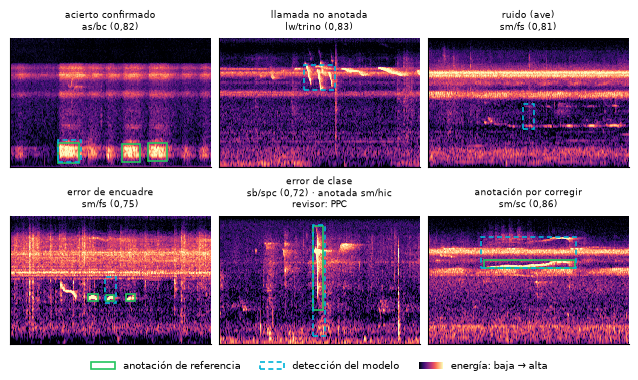

In [14]:
# Un ejemplo por categoría: la caja de mayor confianza; en el ruido, entre las que el revisor
# describe como ave. Caja del modelo discontinua; anotaciones de referencia continuas.
reference_all = in_test[~in_test.requires_review & in_test.label.isin(NAMES)]
EXAMPLES = {
    "acierto confirmado": items.iov == "acierto confirmado",
    "llamada no anotada": items.stratum.isin(NONE_STRATA) & (items.answer == "correct"),
    "ruido (ave)": (items.answer == "no") & items.comment.str.lower().str.contains("bird"),
    "error de encuadre": (items.iov == "error de encuadre") & (items.stratum == BOX),
    "error de clase": items.iov == "error de clase",
    "anotación por corregir": items.iov == "anotación por corregir",
}
fig, axes = plt.subplots(2, 3, figsize=(ANCHO, 3.7), layout="constrained")
for ax, (name, mask) in zip(axes.flat, EXAMPLES.items(), strict=True):
    item = items[mask].sort_values("score", ascending=False).iloc[0]
    path = RAW_DIR / item.recording
    start = max(0.0, (item[BEGIN] + item[END] - P.clip_len_s) / 2)
    espectrograma(ax, cargar(path if path.exists() else CHECK_AUDIO / path.name, start), start)
    near = reference_all[(reference_all.recording == item.recording)
                         & (reference_all.end_time_s > start) & (reference_all.begin_time_s < start + P.clip_len_s)]
    for a in near.itertuples():
        caja(ax, a.begin_time_s, a.end_time_s, a.low_freq_hz, a.high_freq_hz)
    caja(ax, item[BEGIN], item[END], item[LOW], item[HIGH], modelo=True)
    note = re.sub(r"[-,]?\s*mis+ing selections? (of|in)? ?vocalizati?ons?\w*", "", item.comment, flags=re.I).strip(" -,\n")
    detail = f"{item.label} ({item.score:.2f})".replace(".", ",")
    if isinstance(item.annotated_as, str) and item.annotated_as != item.label:
        detail += f" · anotada {item.annotated_as}"
    if name == "error de clase" and note:
        detail += f"\nrevisor: {note}"
    ax.set_title(f"{name}\n{detail}", fontsize=6.5)
    ax.set(xticks=[], yticks=[], xlabel="", ylabel="")
leyenda(fig, anotada("anotación de referencia"), predicha(), energia=True)
OUT.figura(fig, "revision_ejemplos")

In [15]:
# Tarea 3 (calidad del corpus), si volvió
CONFIRMS = {"missing": {"correct", "other", "box"}, "spurious": {"no"}, "label": {"other"}, "location": {"box"}}
if list(ANSWERS.rglob("boxes*")) and (quality := read_answers("Q")).shape[0]:
    findings = pd.read_csv(DATA / "dataset_quality_key.csv")
    resolved = findings.merge(quality[["ID", "answer"]], on="ID", validate="one_to_one")
    rate = {k: g.answer.isin(CONFIRMS[k]).mean() for k, g in resolved.groupby("issue")}
    OUT.valores |= {
        "uQFindings": number(len(findings)),
        "uQReviewed": number(len(resolved)),
        **{f"uQ{k.capitalize()}Confirmed": percent(v, 0) for k, v in rate.items()},
        "uQOmissionsEst": number(rate.get("missing", 0) * (findings.issue == "missing").sum()),
    }

erratas: {}


In [16]:
# Tarea 1: horas de la planilla (las notas, que traen nombres, no se leen)
def seconds(clock: pd.Series) -> pd.Series:
    # «14:05», «14:05:30» o la fracción del día con que una planilla guarda una hora
    def one(text: str) -> float:
        if ":" not in text:
            return float(text) * 86400
        parts = [float(x) for x in text.split(":")]
        return parts[0] * 3600 + parts[1] * 60 + (parts[2] if len(parts) > 2 else 0.0)
    return clock.str.strip().map(one)


blocks = pd.read_csv(DATA / "timed_session_folders.csv")
sheets = sorted([*ANSWERS.rglob("times*.csv"), *ANSWERS.rglob("times*.xlsx")])
times = pd.concat(read_sheet(p)[["folder", "start_time", "end_time", "minutes_paused"]] for p in sheets)
times = times[(times.folder != "") & (times.start_time != "")].copy()
times["work_s"] = ((seconds(times.end_time) - seconds(times.start_time)) % 86400
                   - pd.to_numeric(times.minutes_paused, errors="coerce").fillna(0) * 60)
audio = blocks.groupby(["folder", "condition"], as_index=False).agg(
    duration_s=("duration_s", "sum"), recordings=("recording", "size"),
    annotations=("n_annotations", "sum"), proposals=("n_proposals", "sum"))
timed = times.merge(audio, on="folder", validate="one_to_one").sort_values("folder")
timed["min_per_h"] = timed.work_s / 60 / (timed.duration_s / 3600)
pooled = timed.groupby("condition")[["work_s", "duration_s", "recordings", "annotations", "proposals"]].sum()
pooled["min_per_h"] = pooled.work_s / 60 / (pooled.duration_s / 3600)
timed[["folder", "condition", "work_s", "duration_s", "min_per_h"]].round(1)

,folder,condition,work_s,duration_s,min_per_h
0,1_manual,manual,9720.0,351.2,1660.6
1,2_assisted,assisted,6660.0,352.1,1134.9
2,3_assisted,assisted,6360.0,360.0,1060.0
3,4_manual,manual,2880.0,363.1,475.9


In [17]:
CONDITION = {"manual": "Manual", "assisted": "Asistida"}


def session_row(first: str, row: pd.Series, condition: str) -> list[str]:
    return [first, number(row.recordings), number(row.duration_s / 60, 1), number(row.annotations),
            number(row.proposals) if condition == "assisted" else "--",
            number(row.work_s / 60), number(row.min_per_h)]


rows = [session_row(f"{r.folder.split('_')[0]} & {CONDITION[r.condition]}", r, r.condition)
        for _, r in timed.iterrows()]
rows += [r"\midrule"] + [session_row(r"\multicolumn{2}{@{}l}{" + CONDITION[c] + ", las dos carpetas}",
                                      pooled.loc[c], c) for c in ["manual", "assisted"]]
OUT.tabla("sesion", rows)
OUT.valores |= {
    "uMinManual": number(pooled.min_per_h["manual"]),
    "uMinAssisted": number(pooled.min_per_h["assisted"]),
    "uTimeRatio": number(pooled.min_per_h["assisted"] / pooled.min_per_h["manual"], 2),
    "uWorkManual": number(pooled.work_s["manual"] / 60),
    "uWorkAssisted": number(pooled.work_s["assisted"] / 60),
    "uSessionMinutes": number(blocks.duration_s.sum() / 60, 1),
    "uSessionRecordings": number(len(blocks)),
    "uSessionAnnotations": number(blocks.n_annotations.sum()),
    "uFolderMinLow": number(timed.min_per_h.min()),
    "uFolderMinHigh": number(timed.min_per_h.max()),
    "uFolderAudioLow": number(timed.duration_s.min() / 60, 1),
    "uFolderAudioHigh": number(timed.duration_s.max() / 60, 1),
}

In [18]:
# Las tablas entregadas: la que el revisor guardó para cada grabación (la del modelo sin cambios
# cuenta como aceptada), limpiada con las reglas del equipo. Una tabla vacía no se descarta.
RAVEN = dict(zip(CLEANED, [BEGIN, END, LOW, HIGH], strict=True))
returned = [p for p in ANSWERS.rglob("*.txt") if not p.name.endswith(".boxes.txt")]


def saved_table(recording: str, folder: str) -> Path:
    stem, model = Path(recording).stem, SESSION / folder / f"{Path(recording).stem}.model.txt"
    found = [p for p in returned if p.name.startswith(stem)]
    edited = [p for p in found if not (model.exists() and p.read_bytes() == model.read_bytes())]
    return max(edited or found, key=lambda p: p.stat().st_mtime)


def delivered(path: Path) -> pd.DataFrame:
    raw = pd.read_csv(path, sep="\t")
    if raw.empty:
        return pd.DataFrame(columns=[BEGIN, END, LOW, HIGH, "label", "requires_review"])
    written = raw[SPECIES].astype(str).str.strip().str.lower()
    table = pd.concat(clean_annotations(rows, str(code)) for code, rows in raw.groupby(written))
    label = (table["species"] + "/" + table["call_type"].fillna("")).replace(dataset["joined_labels"])
    return table.rename(columns=RAVEN).assign(label=label)


tables = [delivered(saved_table(r, f)).assign(recording=r, folder=f, condition=c, **{SCORE: 1.0})
          for r, f, c in zip(blocks.recording, blocks.folder, blocks.condition, strict=True)]
empty = [c for t, c in zip(tables, blocks.condition, strict=True) if t.empty]
outputs = pd.concat([t for t in tables if len(t)], ignore_index=True)
outputs["requires_review"] = outputs.requires_review.fillna(False).astype(bool)
session_annotations = annotations[annotations.recording.isin(blocks.recording)]
reference = session_annotations[~session_annotations.requires_review & session_annotations.label.isin(NAMES)]
detections = pd.read_csv(DATA / "test_detections.csv")
model_session = detections[detections.recording.isin(blocks.recording)].merge(
    blocks[["recording", "folder", "condition"]], on="recording")
pd.Series(empty).value_counts()

manual      9
assisted    5
Name: count, dtype: int64

In [19]:
def grade(boxes: pd.DataFrame, condition: str) -> dict[str, float]:
    recordings = blocks.recording[blocks.condition == condition]
    ref = reference[reference.recording.isin(recordings)]
    known = boxes[boxes.recording.isin(recordings) & boxes.label.isin(NAMES)]
    known = known[~known.requires_review] if "requires_review" in known else known
    hits = categorize(known, ref, NAMES).query("category == @MATCH")
    return {"cobertura": hits.annotation.nunique() / len(ref), "precisión": len(hits) / len(known)}


quality = pd.DataFrame({f"{who} {c}": grade(b, c) for c in ["manual", "assisted"]
                        for who, b in [("revisor", outputs), ("modelo", model_session)]}).T
OUT.valores |= {
    "uSessionRef": number(len(reference)),
    "uEmptyTables": number(len(empty)),
    "uEmptyManual": number(empty.count("manual")),
    "uEmptyAssisted": number(empty.count("assisted")),
    **{f"u{who}{field}{cond.capitalize()}": number(quality.loc[f"{key} {cond}", col], 2)
       for who, key in [("", "revisor"), ("Model", "modelo")]
       for field, col in [("Recall", "cobertura"), ("Precision", "precisión")]
       for cond in ["manual", "assisted"]},
}
quality.round(3)

,cobertura,precisión
revisor manual,0.416,0.451
modelo manual,0.820,0.435
revisor assisted,0.602,0.624
modelo assisted,0.739,0.428


In [20]:
# Qué se hizo con cada propuesta en la condición asistida: igual (IoU ≥ 0,9 y su clase),
# corregida (IoU ≥ 0,3) o borrada; y las cajas agregadas (IoU < 0,3 con todas las propuestas)
graded_model = categorize(model_session[model_session.label.isin(NAMES)], reference, NAMES)
fates, added = [], []
for recording, folder in blocks.loc[blocks.condition == "assisted", ["recording", "folder"]].itertuples(index=False):
    model = graded_model[graded_model.recording == recording]
    assert len(model) == len(pd.read_csv(SESSION / folder / f"{Path(recording).stem}.model.txt", sep="\t"))
    final = outputs[outputs.recording == recording]
    if model.empty or final.empty:
        fates += [("deleted", c) for c in model.category]
        added.append(final)
        continue
    iou = box_iou(xyxy(model, [BEGIN, END, LOW, HIGH]), xyxy(final, [BEGIN, END, LOW, HIGH]))
    best, which = iou.max(dim=1)
    same = [final.label.iloc[j] == lab for j, lab in zip(which.tolist(), model.label, strict=True)]
    fates += [("kept" if v >= 0.9 and s else "edited" if v >= 0.3 else "deleted", c)
              for v, s, c in zip(best.tolist(), same, model.category, strict=True)]
    added.append(final[(iou.max(dim=0).values < 0.3).numpy()])
fates = pd.DataFrame(fates, columns=["fate", "category"])
added = pd.concat(added)
added_known = added[added.label.isin(NAMES) & ~added.requires_review]
share_fate = fates.fate.value_counts(normalize=True)
hit_fates = fates[fates.category == MATCH].fate.value_counts()
OUT.valores |= {
    "uProposals": number(len(fates)),
    **{f"uProposals{name}": percent(share_fate.get(f, 0), 0) for f, name in
       [("kept", "Kept"), ("edited", "Edited"), ("deleted", "Deleted")]},
    **{f"uProposals{name}N": number((fates.fate == f).sum()) for f, name in
       [("kept", "Kept"), ("edited", "Edited"), ("deleted", "Deleted")]},
    "uProposalsHit": number((fates.category == MATCH).sum()),
    **{f"uProposalsHit{name}": number(hit_fates.get(f, 0)) for f, name in
       [("kept", "Kept"), ("edited", "Edited"), ("deleted", "Deleted")]},
    "uBoxesAdded": number(len(added)),
    "uBoxesAddedKnown": number(len(added_known)),
    "uBoxesAddedHits": number(categorize(added_known, reference, NAMES).category.eq(MATCH).sum()),
}
pd.crosstab(fates.category, fates.fate, margins=True)

fate,deleted,edited,kept,All
category,,,,
box,47,0,0,47
match,25,16,24,65
none,32,2,6,40
All,104,18,30,152


In [21]:
# Costo de la máquina (GPU: capítulo 5; CPU: la corrida que armó el paquete) y lo que entrega
def covered_seconds(spans: pd.DataFrame) -> float:
    total, end = 0.0, -np.inf
    for begin, finish in sorted(zip(spans[BEGIN], spans[END], strict=True)):
        total += max(finish - max(begin, end), 0.0)
        end = max(end, finish)
    return total


covered = sum(covered_seconds(g) for _, g in detections.groupby("recording"))
assisted = blocks[blocks.condition == "assisted"]
OUT.valores |= {
    "uCpuMinPerHour": number(cpu.seconds.sum() / 60 / (cpu.duration_s.sum() / 3600), 1),
    "uGpuMinPerHour": CH5["rGpuMinYol"],
    "uProposalsPerHour": number(len(detections) / HOURS),
    "uProposalsPerHourBox": number(len(population) / HOURS),
    "uAudioWithoutProposals": percent(1 - covered / cpu.duration_s.sum(), 0),
    "uSessionProposalsPerHour": number(assisted.n_proposals.sum() / (assisted.duration_s.sum() / 3600)),
}

In [22]:
OUT.macros(conservar=False)

uCatUnannotated                507
uCatNoise                      138
uCatFraming                    117
uCatClass                       72
uCatFix                        107
                             ...  
uGpuMinPerHour                0,12
uProposalsPerHour           1\,327
uProposalsPerHourBox           971
uAudioWithoutProposals      65\,\%
uSessionProposalsPerHour       768
Length: 158, dtype: str